# 3. Scaling study in exact simulation, 20 to 156 qubits

Noiseless projected quantum kernel against tuned classical models, on the ibm_fez lattice.

- Train on 200 TCGA-BRCA tumors. Score on 200 held-out TCGA tumors and on 400 METABRIC tumors.
- Five resamples. Genes are chosen on the training tumors only. Every model sees the same n genes.
- PQK depth and bandwidth are chosen by cross-validation on the training set.

Each experiment reads its saved result file. Set the matching `RERUN_*` flag to recompute.
`N_JOBS` is the number of processes; one resample runs per process.

In [2]:
import os, sys
from pathlib import Path
# Find the project folder (the one holding the pqk100 package), wherever Jupyter or VS Code started
def _find_root():
    starts = [Path(p).parent for p in [globals().get("__vsc_ipynb_file__")] if p]
    starts += [Path.cwd(), Path(r"D:\Active Research Projects\PQK100")]
    for s in starts:
        for p in [s, *s.parents]:
            if (p / "pqk100" / "__init__.py").exists() and (p / "credits").is_dir():
                return p.resolve()
    raise RuntimeError(f"Cannot find the PQK100 project folder from {Path.cwd()}. "
                       "Set ROOT = Path(r'D:\\Active Research Projects\\PQK100') by hand in this cell.")
ROOT = _find_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("project folder:", ROOT)

import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

from pqk100 import study, report
from pqk100.backends import local_backend

backend = local_backend()            # FakeFez: fixes which qubits and couplers the feature map uses
N_JOBS = 2

RERUN_SWEEP    = False               # about 45 minutes with 2 processes
RERUN_ABLATION = False               # about 10 minutes
RERUN_PROXY    = False               # about 8 minutes
RERUN_ROBUST   = False               # about 6 minutes

def cached(path, rerun, fn):
    if rerun or not os.path.exists(path):
        return fn(path)
    return pd.read_csv(path)

project folder: D:\Active Research Projects\PQK100


## 3.1 The sweep

Sizes 20, 40, 60, 80, 100, 127, 156. Repetitions 1, 2, 3. Bandwidths 0.25, 0.5, 1.0.

In [3]:
sweep = cached("results/scaling.csv", RERUN_SWEEP,
               lambda p: study.scaling_sweep(seeds=(0, 1, 2, 3, 4), backend=backend, out=p, n_jobs=N_JOBS))
print(len(sweep), "rows,", sweep.seed.nunique(), "resamples, lattice:", sweep.lattice.iloc[0])

425 rows, 5 resamples, lattice: fake_fez


## 3.2 AUC against number of qubits

"PQK" is the kernel whose depth and bandwidth had the best cross-validated AUC on the training set, per resample and size.
Bars are one standard error over resamples.

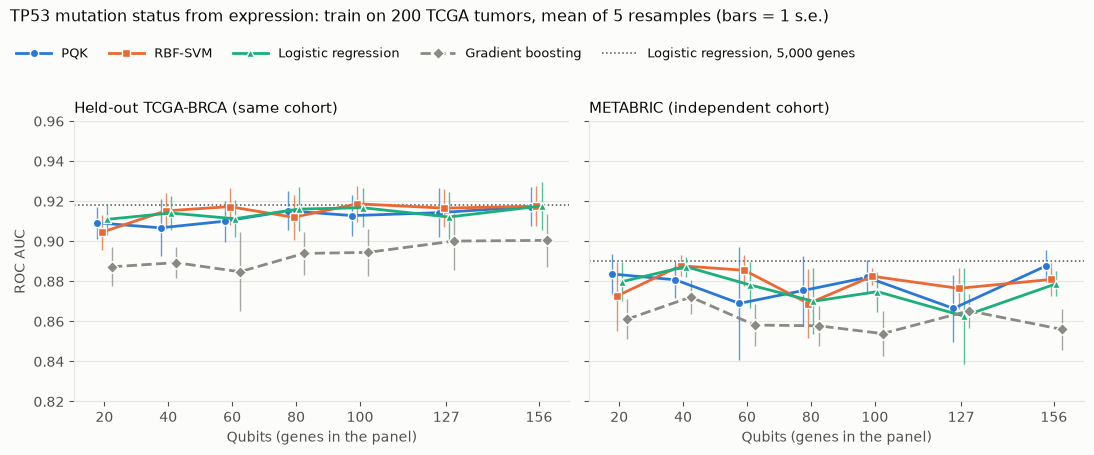

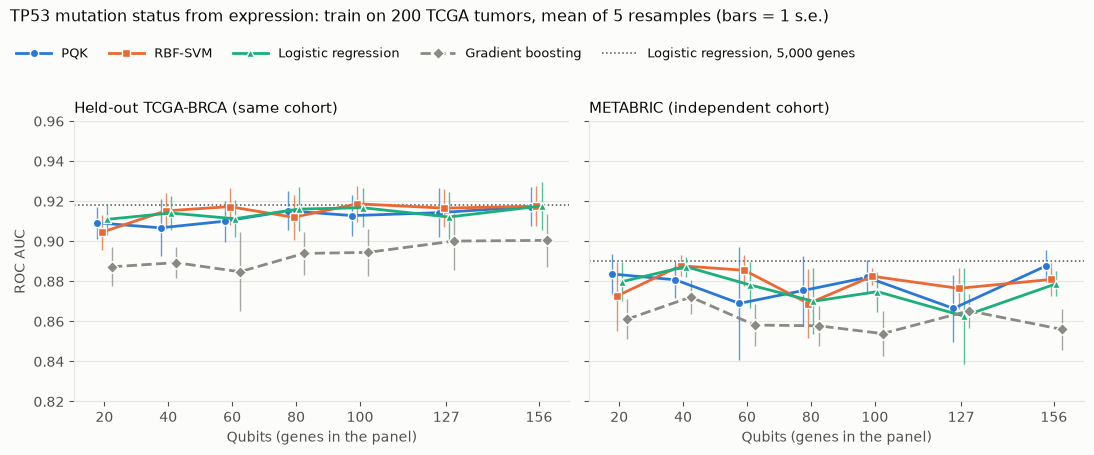

In [4]:
fig = report.fig_scaling(sweep)
fig.savefig("results/scaling_auc.png", dpi=170)
fig

In [5]:
t = report.main_table(sweep)
show = pd.concat({"held-out TCGA": t["in_auc"]["mean"], "METABRIC": t["ext_auc"]["mean"]}, axis=1).round(3)
show = show.rename(columns={"pqk_selected": "PQK", "rbf_svm": "RBF-SVM", "logreg": "LogReg", "gbm": "GBM"})
show

held-out TCGA                       METABRIC                      
model           GBM LogReg    PQK RBF-SVM      GBM LogReg    PQK RBF-SVM
n                                                                       
20            0.887  0.911  0.909   0.904    0.861  0.880  0.884   0.873
40            0.889  0.914  0.907   0.915    0.872  0.887  0.881   0.888
60            0.885  0.911  0.910   0.917    0.858  0.878  0.869   0.886
80            0.894  0.916  0.915   0.912    0.858  0.870  0.875   0.869
100           0.894  0.917  0.913   0.919    0.854  0.875  0.882   0.883
127           0.900  0.912  0.914   0.917    0.865  0.863  0.866   0.876
156           0.900  0.918  0.917   0.917    0.856  0.879  0.888   0.881

In [6]:
ref = report.all_genes_reference(sweep)
print(f"Reference, logistic regression on all 5,000 prefiltered genes: {ref.in_auc:.3f} held-out TCGA, {ref.ext_auc:.3f} METABRIC")

Reference, logistic regression on all 5,000 prefiltered genes: 0.918 held-out TCGA, 0.890 METABRIC


## 3.3 Paired differences

PQK minus a classical model, paired by resample. Mean and standard error over the five resamples.
The resamples share the same two cohorts, so the standard errors are optimistic.

In [7]:
d = report.paired_diff(sweep)
d["value"] = d.apply(lambda r: f"{r['mean']:+.3f} ± {r['se']:.3f}", axis=1)
d["vs"] = d.vs.map({"rbf_svm": "vs RBF-SVM", "logreg": "vs LogReg"}); d["metric"] = d.metric.map({"in_auc": "held-out TCGA", "ext_auc": "METABRIC"})
d.pivot_table(index="n", columns=["vs", "metric"], values="value", aggfunc="first")

vs           vs LogReg                      vs RBF-SVM                
metric        METABRIC   held-out TCGA        METABRIC   held-out TCGA
n                                                                     
20      +0.004 ± 0.002  -0.002 ± 0.002  +0.011 ± 0.008  +0.005 ± 0.008
40      -0.007 ± 0.005  -0.007 ± 0.007  -0.007 ± 0.005  -0.008 ± 0.006
60      -0.009 ± 0.018  -0.001 ± 0.006  -0.017 ± 0.021  -0.007 ± 0.007
80      +0.005 ± 0.006  -0.001 ± 0.002  +0.006 ± 0.002  +0.003 ± 0.002
100     +0.007 ± 0.006  -0.004 ± 0.003  -0.001 ± 0.005  -0.006 ± 0.004
127     +0.004 ± 0.009  +0.002 ± 0.002  -0.010 ± 0.007  -0.002 ± 0.004
156     +0.009 ± 0.006  -0.000 ± 0.004  +0.007 ± 0.002  -0.000 ± 0.001

## 3.4 What cross-validation selects

Count of (resample, size) pairs for each depth and bandwidth.

In [8]:
report.selection_counts(sweep)

bandwidth,0.25,0.50
reps,,
1.0,17,2
2.0,6,1
3.0,5,4


## 3.5 Depth and bandwidth

Mean over resamples and sizes. `bloch_norm` near 1 means the qubits are close to a product state.
`geo_diff` is the geometric difference to the tuned classical RBF kernel (Huang et al. 2021); it should be compared with sqrt(200) = 14.

In [9]:
report.depth_bandwidth(sweep).round(3)

cv_auc  in_auc  ext_auc  bloch_norm  feature_spread  geo_diff  align_q
reps bandwidth                                                                        
1.0  0.25        0.934   0.916    0.882       0.994           0.095     1.117    0.513
     0.50        0.931   0.912    0.878       0.927           0.191     1.215    0.509
     1.00        0.901   0.885    0.852       0.692           0.258     1.808    0.202
2.0  0.25        0.933   0.915    0.880       0.994           0.113     1.243    0.510
     0.50        0.925   0.908    0.880       0.936           0.228     1.324    0.467
     1.00        0.869   0.860    0.819       0.752           0.328     1.933    0.177
3.0  0.25        0.933   0.915    0.881       0.981           0.207     1.228    0.516
     0.50        0.925   0.902    0.870       0.883           0.320     1.593    0.443
     1.00        0.884   0.874    0.823       0.698           0.351     1.279    0.111

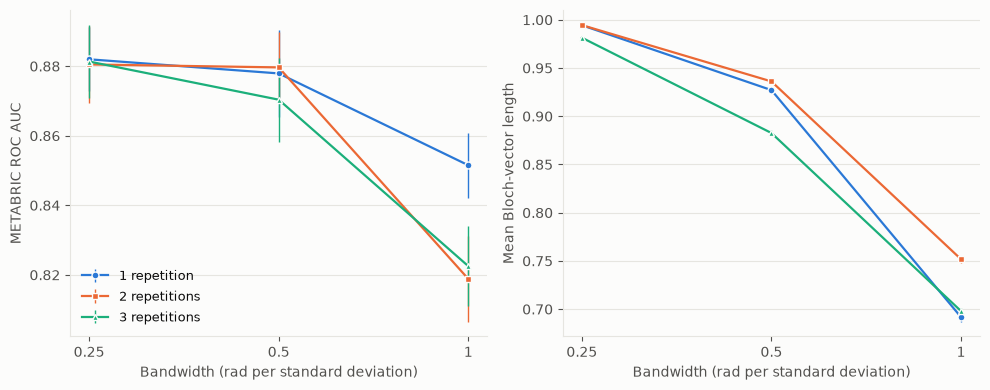

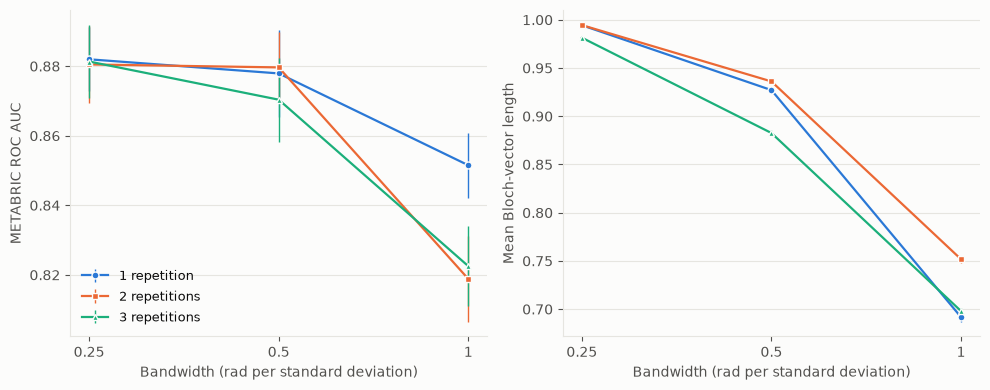

In [10]:
report.fig_bandwidth(sweep)

## 3.6 Concentration with qubit count

At fixed depth each feature depends only on its light cone, so nothing should change with n.

In [11]:
c = report.concentration_by_n(sweep, bandwidth=0.5).round(4)
c.unstack("reps")[["bloch_norm", "feature_spread", "d2_cv"]]

bloch_norm                 feature_spread                   d2_cv                
reps        1.0     2.0     3.0            1.0     2.0     3.0     1.0     2.0     3.0
n                                                                                     
20       0.9269  0.9369  0.8848         0.1906  0.2278  0.3195  0.6323  0.5871  0.4083
40       0.9266  0.9372  0.8840         0.1910  0.2291  0.3207  0.5972  0.5725  0.3716
60       0.9278  0.9371  0.8852         0.1908  0.2282  0.3201  0.5779  0.5572  0.3513
80       0.9285  0.9371  0.8841         0.1909  0.2280  0.3205  0.5590  0.5306  0.3348
100      0.9291  0.9379  0.8846         0.1911  0.2286  0.3218  0.5427  0.5144  0.3240
127      0.9285  0.9368  0.8836         0.1912  0.2283  0.3223  0.5262  0.4906  0.3106
156      0.9220  0.9294  0.8716         0.1908  0.2270  0.3167  0.5056  0.4689  0.2827

## 3.7 Entanglement ablation

Four comparisons on the same data: the PQK, the PQK with its two-qubit gates removed, RBF-SVM, and RBF-SVM on inputs clipped at three standard deviations.
Run under both normalizations.

In [12]:
abl = {s: cached(f"results/ablation_{s}.csv", RERUN_ABLATION,
                 lambda p, s=s: study.ablation(scaling=s, backend=backend, out=p, n_jobs=N_JOBS)) for s in ("cohort", "rank")}
for s, a in abl.items():
    print(f"\nnormalization: {s}   (AUC, mean over {a.seed.nunique()} resamples)")
    print(a.groupby(["n", "model"])[["in_auc", "ext_auc"]].mean().round(3).unstack("n").to_string())


normalization: cohort   (AUC, mean over 5 resamples)
                        in_auc               ext_auc              
n                          20     100    156     20     100    156
model                                                             
Logistic regression      0.911  0.917  0.918   0.880  0.875  0.879
PQK                      0.910  0.915  0.916   0.884  0.880  0.886
PQK, entanglers removed  0.911  0.916  0.916   0.882  0.880  0.881
RBF-SVM                  0.904  0.919  0.917   0.873  0.883  0.881
RBF-SVM, clipped inputs  0.912  0.920  0.917   0.881  0.884  0.883

normalization: rank   (AUC, mean over 5 resamples)
                        in_auc               ext_auc              
n                          20     100    156     20     100    156
model                                                             
Logistic regression      0.907  0.923  0.920   0.873  0.877  0.874
PQK                      0.908  0.920  0.920   0.877  0.848  0.876
PQK, entanglers removed

## 3.8 Shot-noise and gate-error proxy

At the feature maps selected in 3.4. Each expectation value is shrunk by (1 - CZ error) to the power of the CZ count in its light cone, then sampled with a finite number of shots.
This is a planning tool for the shot budget. It ignores crosstalk, leakage, and readout bias.

In [13]:
proxy = cached("results/noise_proxy.csv", RERUN_PROXY,
               lambda p: study.noise_proxy(sweep, shots=(4096, 1024, 256), backend=backend, out=p, n_jobs=N_JOBS))
print(f"CZ error used: {proxy.eps_cz.iloc[0]:.4f} (median of the {backend.name} snapshot)")
proxy["shots"] = proxy.shots.astype(str)
proxy.pivot_table(index="n", columns="shots", values="ext_auc").round(3)[["exact", "4096", "1024", "256"]]

CZ error used: 0.0039 (median of the fake_fez snapshot)


shots,exact,4096,1024,256
n,,,,
20,0.884,0.884,0.875,0.882
40,0.881,0.889,0.885,0.880
60,0.869,0.865,0.866,0.859
80,0.875,0.877,0.872,0.890
100,0.882,0.878,0.879,0.882
127,0.866,0.865,0.876,0.872
156,0.888,0.883,0.887,0.888


## 3.9 Robustness: a second feature map, and rank normalization

Three resamples, three sizes.

In [14]:
rob = {"ry_cz map, cohort normalization": cached("results/robust_rycz.csv", RERUN_ROBUST,
            lambda p: study.scaling_sweep(seeds=(0, 1, 2), sizes=(20, 100, 156), reps=(1, 2), bandwidths=(0.25, 0.5), fmap="ry_cz", backend=backend, out=p, n_jobs=N_JOBS)),
       "zz map, rank normalization": cached("results/robust_rank.csv", RERUN_ROBUST,
            lambda p: study.scaling_sweep(seeds=(0, 1, 2), sizes=(20, 100, 156), reps=(1, 2), bandwidths=(0.25, 0.5), scaling="rank", backend=backend, out=p, n_jobs=N_JOBS))}
for name, r in rob.items():
    t = report.main_table(r)
    print(f"\n{name}  (AUC, mean of {r.seed.nunique()} resamples)")
    print(pd.concat({"held-out TCGA": t["in_auc"]["mean"], "METABRIC": t["ext_auc"]["mean"]}, axis=1).round(3).to_string())


ry_cz map, cohort normalization  (AUC, mean of 3 resamples)
      held-out TCGA                             METABRIC                            
model           gbm logreg pqk_selected rbf_svm      gbm logreg pqk_selected rbf_svm
n                                                                                   
20            0.897  0.921        0.909   0.910    0.856  0.875        0.866   0.864
100           0.906  0.923        0.922   0.926    0.837  0.865        0.881   0.880
156           0.917  0.925        0.916   0.921    0.842  0.874        0.874   0.878

zz map, rank normalization  (AUC, mean of 3 resamples)
      held-out TCGA                             METABRIC                            
model           gbm logreg pqk_selected rbf_svm      gbm logreg pqk_selected rbf_svm
n                                                                                   
20            0.904  0.922        0.921   0.921    0.837  0.865        0.872   0.868
100           0.918  0.931       